In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/nhatanhadr/xes3g5m/qid2content_emb.json
/kaggle/input/datasets/nhatanhadr/xes3g5m/train_valid_sequences_quelevel.csv
/kaggle/input/datasets/nhatanhadr/xes3g5m/questions.json
/kaggle/input/datasets/nhatanhadr/xes3g5m/qid2analysis_emb.json
/kaggle/input/datasets/nhatanhadr/xes3g5m/test_quelevel.csv
/kaggle/input/datasets/nhatanhadr/xes3g5m/cid2content_emb.json
/kaggle/input/datasets/nhatanhadr/xes3g5m/test_window_sequences_quelevel.csv
/kaggle/input/datasets/nhatanhadr/xes3g5m/test.csv
/kaggle/input/datasets/nhatanhadr/xes3g5m/kc_routes_map.json
/kaggle/input/datasets/nhatanhadr/xes3g5m/test_question_window_sequences.csv
/kaggle/input/datasets/nhatanhadr/xes3g5m/train_valid_sequences.csv


In [2]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import torch
import torch.nn as nn
import random
from torch.utils.data import Dataset
from collections import defaultdict
from tqdm import tqdm   # thêm dòng này

# 1. Config

In [3]:
config = {
    "data_train_valid_path": "/kaggle/input/datasets/nhatanhadr/xes3g5m/train_valid_sequences.csv",
    "data_test_path": "/kaggle/input/datasets/nhatanhadr/xes3g5m/test_question_window_sequences.csv",

    # Kích thước dataset — giữ nguyên theo xes3g5m
    "num_concepts": 865,
    "num_questions": 7652,

    # Kiến trúc model — bổ sung, dùng giá trị mặc định gốc của DTransformer paper
    "d_model": 128,
    "d_ff": 256,
    "num_attn_heads": 4,
    "n_know": 16,
    "n_blocks": 3,
    "lambda_cl": 0.1,
    "hard_neg": True,

    # Training
    "dropout": 0.3,
    "lr": 1e-3,
    "batch_size": 32,
    "num_epochs": 50,
    "patience": 7,
    
}

# 2. Dataset & DataLoader

In [4]:
df_train_valid = pd.read_csv(config['data_train_valid_path'])
df_test = pd.read_csv(config['data_test_path'])

print(f"Train: {len(df_train_valid)}")
print(f"Test: {len(df_test)}")

Train: 33397
Test: 697697


# 3. Dataset & DataLoader

In [5]:
def parse_seq(s):
    return list(map(int, s.strip().split(',')))

class DTransformerDataset(Dataset):
    def __init__(self, df, num_concepts, fold=None, is_train=True):

        if fold is not None:
            if is_train:
                df = df[df['fold'] != fold]
            else:
                df = df[df['fold'] == fold] 

        self.questions = [parse_seq(x) for x in df['questions']]
        self.concepts = [parse_seq(x) for x in df['concepts']]
        self.responses = [parse_seq(x) for x in df['responses']]
        self.selectmasks= [parse_seq(x) for x in df['selectmasks']]

        self.qidxs = (
            [parse_seq(x) for x in df['qidxs']]
            if 'qidxs' in df.columns else [None]*len(df)
        )
        self.num_concepts = num_concepts
        self.len = len(df)

    def __len__(self):
        return self.len

    def __getitem__(self, i):
        q = torch.tensor(self.questions[i], dtype=torch.long).clamp(min=0)
        c = torch.tensor(self.concepts[i], dtype=torch.long).clamp(min=0)
        r = torch.tensor(self.responses[i], dtype=torch.long).clamp(min=0)
        m = torch.tensor(self.selectmasks[i], dtype=torch.long)

        item = {
            "questions": q,
            "concepts": c,
            "responses": r,
            "selectmasks": m
        }
        if self.qidxs[i] is not None:
            item["qidxs"] = torch.tensor(self.qidxs[i], dtype=torch.long)
        return item

# 4. Model Definition

In [6]:
# class DTransformer(nn.Module):
#     def __init__(
#         self,
#         num_questions,
#         num_concepts,
#         d_model=128,
#         d_ff=256,
#         num_attn_heads=8,
#         n_know=16,
#         n_blocks=3,
#         dropout=0.3,
#         lambda_cl=0.1,
#         proj=False,
#         hard_neg=False,
#         window=1,
#         shortcut=False,
#     ):
#         super().__init__()
#         self.num_questions = num_questions
#         self.num_concepts = num_concepts
#         self.dropout_rate = dropout
#         self.lambda_cl = lambda_cl
#         self.hard_neg = hard_neg
#         self.shortcut = shortcut
#         self.n_layers = n_blocks
#         self.window = window
#         d_fc = d_ff
#         self.question_diff_embed = nn.Embedding(num_questions, 1) #()
#         self.concept_diff_embed = nn.Embedding(num_concepts, d_model)
#         self.response_diff_embed = nn.Embedding(2, d_model)
#         self.concept_embed = nn.Embedding(num_concepts, d_model)
#         self.response_embed = nn.Embedding(2, d_model)

#         # Transoformer Encoder
#         self.n_heads = num_attn_heads
#         self.block1 = DTransformerLayer(d_model, self.n_heads, dropout)
#         self.block2 = DTransformerLayer(d_model, self.n_heads, dropout)
#         self.block3 = DTransformerLayer(d_model, self.n_heads, dropout)
#         self.block4 = DTransformerLayer(d_model, self.n_heads, dropout)

#         # Knowledge Encoder
#         self.n_know = n_know
#         self.know_params = nn.Parameter(torch.empty(n_know, d_model))
#         torch.nn.init.uniform_(self.know_params, -1.0, 1.0)

#         # Output Layer
#         self.out = nn.Sequential(
#             nn.Linear(d_model * 2, d_fc),
#             nn.GELU(),
#             nn.Dropout(dropout),
#             nn.Linear(d_fc, d_fc // 2),
#             nn.GELU(),
#             nn.Dropout(dropout),
#             nn.Linear(d_fc // 2, 1),
#         )

#         self.reset()

#         self.proj = nn.Sequential(nn.Linear(d_model, d_model), nn.GELU())

#     def reset(self):
#         for p in self.parameters():
#             if p.size(0) == self.n_pid+1 and self.n_pid>0:
#                 torch.nn.init.constant_(p, 0.)

#     def forward(self, q_emb, s_emb, lens):
#         # q_emb (batch_size, seq_len, d_model)
#         # s_emb (batch_size, seq_len, d_model)
#         # lens (batch_size)
#         if self.n_layers == 1:
#             p, q_scores = self.block1(q_emb, q_emb, s_emb, lens, peek_cur=True)
#         elif self.n_layers == 2:
#             hs, _ = self.block1(s_emb, s_emb, s_emb, lens, peek_cur=True)
#             p, q_scores = self.block2(q_emb, q_emb, hs, peek_cur=True)
#         else:
#             hq, _ = self.block1(q_emb, q_emb, q_emb, lens, peek_cur=True) # (batch_size, seq_len, d_model)
#             hs, _ = self.block2(s_emb, s_emb, s_emb, lens, peek_cur=True) # (batch_size, seq_len, d_model)
#             p, q_scores = self.block3(hq, hq, hs, lens, peek_cur=True) # (batch_size, seq_len, d_model)

#         bs, seqlen, d_model = p.size() # (batch_size, seq_len, d_model)
#         n_know = self.n_know

#         query = (
#             self.know_params[None, :, None, :] # (1, n_know, 1, d_model)
#             .expand(bs, -1, seqlen, -1) # (batch_size, n_know, seq_len, d_model)
#             .contiguous()
#             .view(bs * n_know, seqlen, d_model) # (batch_size * n_know, seq_len, d_model)
#         )

#         hq = hq.unsqueeze(1).expand(-1, n_know, -1, -1).reshape_as(query) # (batch_size * n_know, seq_len, d_model)
#         p = p.unsqueeze(1).expand(-1, n_know, -1, -1).reshape_as(query) # (batch_size * n_know, seq_len, d_model)

#         z, k_scores = self.block4(
#             query, hq, p, torch.repeat_interleave(lens, n_know), peek_cur=False
#         ) # (batch_size * n_know, seq_len, d_model)
#         z = (
#             z.view(bs, n_know, seqlen, d_model)  # unpack dimensions
#             .transpose(1, 2)  # (bs, seqlen, n_know, d_model)
#             .contiguous()
#             .view(bs, seqlen, -1)
#         )
#         k_scores = (
#             k_scores.view(bs, n_know, self.n_heads, seqlen, seqlen)  # unpack dimensions
#             .permute(0, 2, 3, 1, 4)  # (bs, n_heads, seqlen, n_know, seqlen)
#             .contiguous()
#         )
#         return z, q_scores, k_scores # (batch_size, seq_len, n_know * d_model)

#     def base_emb(self, concept_data, target):
#         c_embed_data = self.concept_embed(concept_data)
#         ca_embed_data = self.response_embed(target) + c_embed_data
#         return c_embed_data, ca_embed_data # (batch_size, seq_len, d_model)

#     def embedding(self, concept_data, target, question_data):
#         lens = (target >= 0).sum(dim=1) # (batch_size)
#         c_embed_data, ca_embed_data = base_emb(concept_data, target) # (batch_size, seq_len, d_model)
#         c_embed_diff_data = self.concept_diff_embed(concept_data)
#         q_embed_diff_data = self.question_diff_embed(question_data)
#         q_embed_data = c_embed_data + q_embed_diff_data * c_embed_diff_data
#         ca_diff_embed_data = self.response_diff_embed(target)
#         a_embed_data = ca_embed_data + q_embed_diff_data * (ca_embed_diff_data + c_embed_diff_data)

#         return q_embed_data, a_embed_data, lens, q_embed_diff_data
        
#     def readout(self, z, query):
#         bs, seq_len, _ = query.size()
#         key = (
#             self.know_params[None, None, :, :]
#             .expand(bs, seqlen, -1, -1)
#             .view(bs * seqlen, self.n_know, -1)
#         ) # (bs * seqlen, self.n_know, -1)
#         value = z.reshape(bs * seqlen, self.n_know, -1) # (bs * seqlen, self.n_know, -1)
#         beta = torch.matmul(
#             key,
#             query.reshape(bs * seqlen, -1, 1),
#         ).view(bs * seqlen, 1, self.n_know)  #  (bs * seqlen, 1, self.n_know)
#         alpha = torch.softmax(beta, -1)
#         return torch.matmul(alpha, value).view(bs, seqlen, -1)  # (bs, seqlen, -1)

#     def predict(self, concept_data, target, question_data):
#         q_embed, a_embed, lens, q_embed_diff = self.embedding(concept_data, target, question_data)
#         # (batch_size, seq_len, d_model); (batch_size)
#         z, q_scores, k_scores = self(q_embed, a_embed, lens) # (batch_size, seq_len, n_know * d_model))
#         query = q_emb # (batch_size, seq_len, d_model)
#         h = self.readout(z[:, : query.size(1), :], query)
#         concat_q = torch.cat([q_emb, h], dim=-1)
#         output = self.out(concat_q).squeeze(-1)
#         return output, concat_q, z, q_emb, (p_diff**2).mean() * 1e-3, (q_scores, k_scores)

#     def get_loss(self, concept_data, target, question_data, q_cl=False):
#         c = concept_data.to(device)
#         r = target.to(device)
#         q = question_data.to(device)
#         # (batch_size, seq_len)
#         output, concat_q, _, _, reg_loss, _ = self.predict(c, r, q)
        
        

# class DTransformerLayer(nn.Module):
#     def __init__(self, d_model, n_heads, dropout, kq_same=True):
#         super().__init__()
#         self.masked_attn_head = MultiHeadAttention(d_model, n_heads, kq_same)
#         self.dropout_rate = dropout
#         self.dropout = nn.Dropout(dropout)
#         self.layer_norm = nn.LayerNorm(d_model)

#     def device(self):
#         return next(self.parameter()).device

#     def forward(self, query, key, values, lens, peek_cur=False):
#         # query, key, value (batch_size, seq_len, d_model)
#         # lens (batch_size)
#         seq_len = query.size(1)
#         mask = torch.ones(seq_len, seq_len).tril(0 if peek_cur else -1) # (seq_len, seq_len)
#         mask = mask.bool()[None, None, :, :].to(self.device()) # (1, 1, seq_len, seq_len)
#         if self.training:
#             mask = mask.expand(query.size(0), -1, -1, -1).contiguous() # (batch_size, 1, seq_len, seq_len)
#         query_, scores = self.masked_attn_head(
#             query, key, values, mask, maxout=not peek_cur
#         ) # (batch_size, seq_len, d_model)
#         query = query + self.dropout(query_) # (batch_size, seq_len, d_model)
#         return self.layer_norm(query), scores # (batch_size, seq_len, d_model)

# class MultiHeadAttention(nn.Module):
#     def __init__(self, d_model. n_heads, bias=True):
#         super().__init__()
#         self.d_model = d_model
#         self.d_k = d_model // n_heads
#         self.h = n_heads
#         self.q_linear = nn.Linear(d_model, d_model, bias=bias)
#         self.k_linear = nn.Linear(d_model, d_model, bias=bias)
#         self.v_linear = nn.Linear(d_model, d_model, bias=bias)
#         self.out_proj = nn.Linear(d_model, d_model, bias=bias)
#         self.gamma = nn.Parameter(torch.zeros(n_heads, 1, 1))
#         torch.nn.init.xavier_uniform_(self.gamma)

#     def forward(self, q, k, v, mask, maxout=False):
#         # q, k, v (batch_size, seq_len, d_model)
#         # mask (batch_size, 1, seq_len, seq_len)
#         bs = q.shape[0]
#         q = self.q_linear(q).view(bs, -1, self.h, self.d_k) # (batch_size, seq_len, h, d_k)
#         k = self.k_linear(k).view(bs, -1, self.h, self.d_k) # (batch_size, seq_len, h, d_k)
#         v = self.v_linear(v).view(bs, -1, self.h, self.d_k) # (batch_size, seq_len, h, d_k)
#         k = k.transpose(1, 2) # (batch_size, h, seq_len, d_k)
#         q = q.transpose(1, 2) # (batch_size, h, seq_len, d_k)
#         v = v.transpose(1, 2) # (batch_size, h, seq_len, d_k)

#         v_, scores = attention(
#             q,
#             k,
#             v,
#             mask,
#             self.gamma,
#             maxout,
#         )
#         # v_ (batch_size, h, seq_len, d_k)

#         concat = v_.transpose(1, 2).contiguous().view(bs, -1, self.d_model) # (batch_size, seq_len, d_model)

#         output = self.out_proj(concat) # (batch_size, seq_len, d_model)

#         return output, scores

# def attention(q, k, v, mask, gamma=None, maxout=False):
#     # q, k, v # (batch_size, h, seq_len, d_k)
#     # mask (batch_size, 1, seq_len, seq_len)
#     # gamma (h, 1, 1)
#     d_k = k.size(-1)
#     scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(d_k) # (batch_size, h, seq_len, seq_len)
#     bs, head, seq_len, _ = score.shape

#     x1 = torch.arange(seq_len).float().expand(seq_len, -1).to(gamma.device) # (seq_len, seq_len)
#     x2 = x1.transpose(0, 1).contiguous() # (seq_len, seq_len)

#     with torch.no_grad():
#         scores_ = scores.masked_fill(mask == 0, -1e32) # (batch_size, h, seq_len, seq_len)
#         scores_ = F.softmax(scores_, dim=-1) # (batch_size, h, seq_len, seq_len) (các chỗ không cho nhìn sẽ có weigh = 0)
#         distcum_scores = torch.cumsum(scores_, dim=-1) # (batch_size, h, seq_len, seq_len)
#         disttotal_scores = torch.sum(scores_, dim=-1, keepdim=True) # (batch_size, h, seq_len, 1)
#         position_effect = torch.abs(x1 - x2)[None, None, :, :] # (1, 1, seq_len, seq_len)
#         dist_scores = torch.clamp(
#             (disttotal_scores - distcum_scores) * position_effect, min=0.0
#         )
#         dist_scores = dist_scores.sqrt().detach() # (batch_size, h, seq_len, seq_len)

#     gamma = -1.0 * gamma.abs().unsqueeze(0) #(1, h, 1, 1)
#     total_effect = torch.clamp((dist_score * gamma).exp(), min=-1e-5, max=1e5) # (batch_size, h, seq_len, seq_len)
#     scores *= total_effect # (batch_size, h, seq_len, seq_len)

#     scores.masked_fill_(mask == 0, -1e32) # (batch_size, h, seq_len, seq_len)
#     scores = F.softmax(scores, dim=-1) # (batch_size, h, seq_len, seq_len)
#     scores = scores.masked_fill(mask == 0, 0) # (batch_size, h, seq_len, seq_len)
#     # maxout
#     scale = torch.clamp(1.0 / (scores.max(dim=-1, keepdim=True)[0] + 1e-8), max=5.0) # (batch_size,h,seq_len,1)
#     scores *= scale # (batch_size, h, seq_len, seq_len)
#     output = torch.matmul(scores, v) # (batch_size, h, seq_len, d_k)
#     return output, scores
        
        
        

In [7]:
import math
import random
import torch
from torch import nn
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MIN_SEQ_LEN = 5  # chuỗi ngắn hơn ngưỡng này sẽ bỏ qua augmentation/CL, chỉ tính pred loss thường


class DTransformer(nn.Module):
    def __init__(
        self,
        num_questions,
        num_concepts,
        d_model=128,
        d_ff=256,
        num_attn_heads=8,
        n_know=16,
        n_blocks=3,
        dropout=0.3,
        lambda_cl=0.1,
        proj=False,
        hard_neg=False,
        window=1,
        shortcut=False,
    ):
        super().__init__()
        self.num_questions = num_questions
        self.num_concepts = num_concepts
        self.n_pid = num_questions  # dùng cho reset() giống bản gốc pykt
        self.dropout_rate = dropout
        self.lambda_cl = lambda_cl
        self.hard_neg = hard_neg
        self.shortcut = shortcut
        self.n_layers = n_blocks
        self.window = window
        d_fc = d_ff

        # Embedding layers
        self.question_diff_embed = nn.Embedding(num_questions + 1, d_model)   # uq
        self.concept_diff_embed = nn.Embedding(num_concepts, d_model)         # d_ct
        self.response_diff_embed = nn.Embedding(2, d_model)                   # f_(ct,rt)
        self.concept_embed = nn.Embedding(num_concepts, d_model)              # c_ct
        self.response_embed = nn.Embedding(2, d_model)                        # g_rt
        self.pid_diff_embed = nn.Embedding(num_questions + 1, 1)              # độ khó riêng của mỗi câu hỏi

        # Transformer Encoder (4 block dùng chung kiến trúc DTransformerLayer)
        self.n_heads = num_attn_heads
        self.block1 = DTransformerLayer(d_model, self.n_heads, dropout)
        self.block2 = DTransformerLayer(d_model, self.n_heads, dropout)
        self.block3 = DTransformerLayer(d_model, self.n_heads, dropout)
        # block4 là knowledge-retriever: query (know_params) khác key (hq) nên kq_same=False
        self.block4 = DTransformerLayer(d_model, self.n_heads, dropout, kq_same=False)

        # Knowledge Encoder
        self.n_know = n_know
        self.know_params = nn.Parameter(torch.empty(n_know, d_model))
        torch.nn.init.uniform_(self.know_params, -1.0, 1.0)

        # Output Layer
        self.out = nn.Sequential(
            nn.Linear(d_model * 2, d_fc),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_fc, d_fc // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_fc // 2, 1),
        )

        self.reset()

        self.proj = nn.Sequential(nn.Linear(d_model, d_model), nn.GELU()) if proj else None

    def reset(self):
        for p in self.parameters():
            if p.size(0) == self.n_pid + 1 and self.n_pid > 0:
                torch.nn.init.constant_(p, 0.0)

    # ---------------------------------------------------------------- #
    # Encoder chính: nhận q_emb, s_emb (đã cộng phần difficulty) và lens
    # ---------------------------------------------------------------- #
    def forward(self, q_emb, s_emb, lens):
        # q_emb (batch_size, seq_len, d_model)
        # s_emb (batch_size, seq_len, d_model)
        # lens  (batch_size)
        if self.n_layers == 1:
            hq = q_emb
            p, q_scores = self.block1(q_emb, q_emb, s_emb, lens, peek_cur=True)
        elif self.n_layers == 2:
            hq = q_emb
            hs, _ = self.block1(s_emb, s_emb, s_emb, lens, peek_cur=True)
            p, q_scores = self.block2(hq, hq, hs, lens, peek_cur=True)
        else:
            hq, _ = self.block1(q_emb, q_emb, q_emb, lens, peek_cur=True)  # (bs, seq_len, d_model)
            hs, _ = self.block2(s_emb, s_emb, s_emb, lens, peek_cur=True)  # (bs, seq_len, d_model)
            p, q_scores = self.block3(hq, hq, hs, lens, peek_cur=True)     # (bs, seq_len, d_model)

        bs, seqlen, d_model = p.size()
        n_know = self.n_know

        query = (
            self.know_params[None, :, None, :]           # (1, n_know, 1, d_model)
            .expand(bs, -1, seqlen, -1)                   # (bs, n_know, seq_len, d_model)
            .contiguous()
            .view(bs * n_know, seqlen, d_model)            # (bs * n_know, seq_len, d_model)
        )

        hq = hq.unsqueeze(1).expand(-1, n_know, -1, -1).reshape_as(query)  # (bs * n_know, seq_len, d_model)
        p = p.unsqueeze(1).expand(-1, n_know, -1, -1).reshape_as(query)    # (bs * n_know, seq_len, d_model)

        z, k_scores = self.block4(
            query, hq, p, torch.repeat_interleave(lens, n_know), peek_cur=False
        )  # (bs * n_know, seq_len, d_model)

        z = (
            z.view(bs, n_know, seqlen, d_model)
            .transpose(1, 2)                 # (bs, seqlen, n_know, d_model)
            .contiguous()
            .view(bs, seqlen, -1)             # (bs, seqlen, n_know * d_model)
        )
        k_scores = (
            k_scores.view(bs, n_know, self.n_heads, seqlen, seqlen)
            .permute(0, 2, 3, 1, 4)          # (bs, n_heads, seqlen, n_know, seqlen)
            .contiguous()
        )
        return z, q_scores, k_scores  # (bs, seq_len, n_know * d_model)

    # ---------------------------------------------------------------- #
    # Embedding: concept_data, target (response 0/1), question_data
    # ---------------------------------------------------------------- #
    def base_emb(self, concept_data, target):
        c_embed_data = self.concept_embed(concept_data)            # (bs, seq_len, d_model)
        ca_embed_data = self.response_embed(target) + c_embed_data  # (bs, seq_len, d_model)
        return c_embed_data, ca_embed_data

    def embedding(self, concept_data, target, question_data):
        lens = (target >= 0).sum(dim=1)  # (bs)

        c_embed_data, ca_embed_data = self.base_emb(concept_data, target)

        c_embed_diff_data = self.concept_diff_embed(concept_data)   # d_ct
        q_embed_diff_data = self.question_diff_embed(question_data)  # uq
        p_diff_data = self.pid_diff_embed(question_data)             # độ khó vô hướng của câu hỏi

        # q_embed = c_ct + uq * d_ct  (câu hỏi được "điều chỉnh" bởi độ khó riêng)
        q_embed_data = c_embed_data + p_diff_data * c_embed_diff_data

        ca_diff_embed_data = self.response_diff_embed(target)        # f_(ct,rt)
        a_embed_data = ca_embed_data + p_diff_data * (ca_diff_embed_data + c_embed_diff_data)

        return q_embed_data, a_embed_data, lens, p_diff_data

    def readout(self, z, query):
        bs, seqlen, _ = query.size()
        key = (
            self.know_params[None, None, :, :]
            .expand(bs, seqlen, -1, -1)
            .contiguous()
            .view(bs * seqlen, self.n_know, -1)
        )
        value = z.reshape(bs * seqlen, self.n_know, -1)
        beta = torch.matmul(
            key,
            query.reshape(bs * seqlen, -1, 1),
        ).view(bs * seqlen, 1, self.n_know)
        alpha = torch.softmax(beta, -1)
        return torch.matmul(alpha, value).view(bs, seqlen, -1)

    def predict(self, concept_data, target, question_data, n=1):
        q_embed, a_embed, lens, p_diff = self.embedding(concept_data, target, question_data)
        # q_embed, a_embed: (bs, seq_len, d_model); lens: (bs)

        z, q_scores, k_scores = self(q_embed, a_embed, lens)  # (bs, seq_len, n_know * d_model)

        query = q_embed[:, n - 1:, :]  # dự đoán cho bước T+n
        h = self.readout(z[:, : query.size(1), :], query)

        concat_q = torch.cat([query, h], dim=-1)
        output = self.out(concat_q).squeeze(-1)

        reg_loss = (p_diff ** 2).mean() * 1e-3
        return output, concat_q, z, q_embed, reg_loss, (q_scores, k_scores)

    def get_loss(self, concept_data, target, question_data, selectmask=None):
        c = concept_data.to(device)
        r = target.to(device)
        q = question_data.to(device)

        output, concat_q, z, q_embed, reg_loss, _ = self.predict(c, r, q)

        if selectmask is not None:
            # selectmask: (bs, seq_len) — chỉ giá trị 1 là hợp lệ, tự nó đã loại padding
            mask = selectmask.to(device)[:, : output.size(1)] == 1
        else:
            # không có selectmask thì fallback về cách cũ: bỏ padding (target == -1)
            mask = r[:, : output.size(1)] >= 0

        masked_logits = output[mask]
        masked_labels = r[:, : output.size(1)][mask].float()

        loss = F.binary_cross_entropy_with_logits(
            masked_logits, masked_labels, reduction="mean"
        ) + reg_loss

        preds = torch.sigmoid(output)
        return preds, loss

    def get_cl_loss(self, concept_data, target, question_data, selectmask=None):
        bs = target.size(0)

        c = concept_data.to(device)
        r = target.to(device)
        q = question_data.to(device)
        sm = selectmask.to(device) if selectmask is not None else None

        # chuỗi quá ngắn thì bỏ qua CL, chỉ tính loss dự đoán bình thường
        if sm is not None:
            lens = (sm == 1).sum(dim=1)          # <-- SỬA: dùng selectmask thay vì (r >= 0)
        else:
            lens = (r >= 0).sum(dim=1)
        minlen = lens.min().item()
        if minlen < MIN_SEQ_LEN:
            return self.get_loss(c, r, q, sm)

        # ---- augmentation 1: hoán đổi vị trí một vài cặp tương tác liền kề ----
        c_ = c.clone()
        r_ = r.clone()
        q_ = q.clone()
        for b in range(bs):
            idx = random.sample(
                range(lens[b] - 1), max(1, int(lens[b] * self.dropout_rate))
            )
            for i in idx:
                c_[b, i], c_[b, i + 1] = c_[b, i + 1], c_[b, i]
                r_[b, i], r_[b, i + 1] = r_[b, i + 1], r_[b, i]
                q_[b, i], q_[b, i + 1] = q_[b, i + 1], q_[b, i]

        # ---- augmentation 2: hard negative (đảo response tại vài vị trí) ----
        r_flip = r.clone() if self.hard_neg else r_
        for b in range(bs):
            idx = random.sample(
                range(lens[b]), max(1, int(lens[b] * self.dropout_rate))
            )
            for i in idx:
                r_flip[b, i] = 1 - r_flip[b, i]
        if not self.hard_neg:
            r_ = r_flip

        # ---- forward các phiên bản ----
        output, concat_q, z_1, q_embed, reg_loss, _ = self.predict(c, r, q)
        _, _, z_2, *_ = self.predict(c_, r_, q_)
        if self.hard_neg:
            _, _, z_3, *_ = self.predict(c, r_flip, q)

        # ---- contrastive loss (SimCLR-style trên embedding tri thức z) ----
        sim_input = self.sim(z_1[:, :minlen, :], z_2[:, :minlen, :])
        if self.hard_neg:
            hard_neg_sim = self.sim(z_1[:, :minlen, :], z_3[:, :minlen, :])
            sim_input = torch.cat([sim_input, hard_neg_sim], dim=1)
        cl_target = (
            torch.arange(bs)[:, None]
            .to(self.know_params.device)
            .expand(-1, minlen)
        )
        cl_loss = F.cross_entropy(sim_input, cl_target)

        # ---- prediction loss (có áp dụng selectmask nếu có) ----
        if sm is not None:
            mask = sm[:, : output.size(1)] == 1
        else:
            mask = r[:, : output.size(1)] >= 0
        pred_loss = F.binary_cross_entropy_with_logits(
            output[mask], r[:, : output.size(1)][mask].float(), reduction="mean"
        )

        # ---- (tuỳ chọn) dự đoán thêm T+i cho i trong window, cũng áp dụng selectmask ----
        for i in range(1, self.window):
            label = r[:, i:]
            query = q_embed[:, i:, :]
            h = self.readout(z_1[:, : query.size(1), :], query)
            y = self.out(torch.cat([query, h], dim=-1)).squeeze(-1)

            if sm is not None:
                win_mask = sm[:, i:][:, : label.size(1)] == 1
            else:
                win_mask = label >= 0

            pred_loss = pred_loss + F.binary_cross_entropy_with_logits(
                y[win_mask], label[win_mask].float()
            )

        preds = torch.sigmoid(output)
        loss = pred_loss + cl_loss * self.lambda_cl + reg_loss
        return preds, loss

    def sim(self, z1, z2):
        bs, seqlen, _ = z1.size()
        z1 = z1.unsqueeze(1).view(bs, 1, seqlen, self.n_know, -1)
        z2 = z2.unsqueeze(0).view(1, bs, seqlen, self.n_know, -1)
        if self.proj is not None:
            z1 = self.proj(z1)
            z2 = self.proj(z2)
        return F.cosine_similarity(z1.mean(-2), z2.mean(-2), dim=-1) / 0.05


class DTransformerLayer(nn.Module):
    def __init__(self, d_model, n_heads, dropout, kq_same=True):
        super().__init__()
        self.masked_attn_head = MultiHeadAttention(d_model, n_heads, kq_same)
        self.dropout_rate = dropout
        self.dropout = nn.Dropout(dropout)
        self.layer_norm = nn.LayerNorm(d_model)

    def device(self):
        return next(self.parameters()).device

    def forward(self, query, key, values, lens, peek_cur=False):
        # query, key, value (bs, seq_len, d_model)
        seq_len = query.size(1)
        mask = torch.ones(seq_len, seq_len).tril(0 if peek_cur else -1)  # (seq_len, seq_len)
        mask = mask.bool()[None, None, :, :].to(self.device())           # (1, 1, seq_len, seq_len)
        if self.training:
            mask = mask.expand(query.size(0), -1, -1, -1).contiguous()

        query_, scores = self.masked_attn_head(
            query, key, values, mask, maxout=not peek_cur
        )
        query = query + self.dropout(query_)
        return self.layer_norm(query), scores


class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads, kq_same=True, bias=True):
        super().__init__()
        self.d_model = d_model
        self.d_k = d_model // n_heads
        self.h = n_heads

        self.q_linear = nn.Linear(d_model, d_model, bias=bias)
        if kq_same:
            self.k_linear = self.q_linear
        else:
            self.k_linear = nn.Linear(d_model, d_model, bias=bias)
        self.v_linear = nn.Linear(d_model, d_model, bias=bias)
        self.out_proj = nn.Linear(d_model, d_model, bias=bias)

        self.gamma = nn.Parameter(torch.zeros(n_heads, 1, 1))
        torch.nn.init.xavier_uniform_(self.gamma)

    def forward(self, q, k, v, mask, maxout=False):
        bs = q.shape[0]
        q = self.q_linear(q).view(bs, -1, self.h, self.d_k)
        k = self.k_linear(k).view(bs, -1, self.h, self.d_k)
        v = self.v_linear(v).view(bs, -1, self.h, self.d_k)
        k = k.transpose(1, 2)
        q = q.transpose(1, 2)
        v = v.transpose(1, 2)

        v_, scores = attention(q, k, v, mask, self.gamma, maxout)

        concat = v_.transpose(1, 2).contiguous().view(bs, -1, self.d_model)
        output = self.out_proj(concat)
        return output, scores


def attention(q, k, v, mask, gamma=None, maxout=False):
    # q, k, v (bs, h, seq_len, d_k)
    d_k = k.size(-1)
    scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(d_k)  # (bs, h, seq_len, seq_len)
    bs, head, seq_len, _ = scores.shape

    if gamma is not None:
        x1 = torch.arange(seq_len).float().expand(seq_len, -1).to(gamma.device)
        x2 = x1.transpose(0, 1).contiguous()

        with torch.no_grad():
            scores_ = scores.masked_fill(mask == 0, -1e32)
            scores_ = F.softmax(scores_, dim=-1)
            distcum_scores = torch.cumsum(scores_, dim=-1)
            disttotal_scores = torch.sum(scores_, dim=-1, keepdim=True)
            position_effect = torch.abs(x1 - x2)[None, None, :, :]
            dist_scores = torch.clamp(
                (disttotal_scores - distcum_scores) * position_effect, min=0.0
            )
            dist_scores = dist_scores.sqrt().detach()

        gamma = -1.0 * gamma.abs().unsqueeze(0)
        total_effect = torch.clamp((dist_scores * gamma).exp(), min=1e-5, max=1e5)
        scores = scores * total_effect

    scores = scores.masked_fill(mask == 0, -1e32)
    scores = F.softmax(scores, dim=-1)
    scores = scores.masked_fill(mask == 0, 0)

    if maxout:
        scale = torch.clamp(1.0 / (scores.max(dim=-1, keepdim=True)[0] + 1e-8), max=5.0)
        scores = scores * scale

    output = torch.matmul(scores, v)
    return output, scores


# 5. Compute Metric

In [8]:
from collections import defaultdict
import numpy as np
import torch
from tqdm import tqdm
from sklearn.metrics import roc_auc_score, accuracy_score, mean_squared_error, mean_absolute_error, f1_score, precision_score, recall_score

def compute_metrics(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_pred_binary = (y_pred > 0.5).astype(int)

    if len(np.unique(y_true)) > 1:
        auc = roc_auc_score(y_true, y_pred)
    else:
        auc = 0.5

    acc = accuracy_score(y_true, y_pred_binary)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    f1 = f1_score(y_true, y_pred_binary, zero_division=0)
    precision = precision_score(y_true, y_pred_binary, zero_division=0)
    recall = recall_score(y_true, y_pred_binary, zero_division=0)

    return {
        "auc": auc,
        "acc": acc,
        "rmse": rmse,
        "mae": mae,
        "f1": f1,
        "precision": precision,
        "recall": recall
    }

# 6. Train Loop

In [9]:
def train_epoch(model, train_loader, val_loader, optimizer, device, num_epochs=20, patience=5):
    train_loss_history = []
    valid_loss_history = []
    valid_auc_history = []
    all_preds = []
    all_labels = []
    
    best_auc = 0.0
    best_state = None
    no_improve = 0

    for epoch in range(num_epochs):
        # TRAIN
        model.train()
        total_loss = 0.0
        n_batches = 0

        pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} - Train", leave=False)
        for batch in pbar:
            questions = batch["questions"].to(device)
            concepts = batch["concepts"].to(device)
            responses = batch["responses"].to(device)
            selectmasks = batch["selectmasks"].to(device)
            optimizer.zero_grad(set_to_none=True)
            preds, loss = model.get_cl_loss(concepts, responses, questions, selectmasks)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=50.0)
            optimizer.step()
            total_loss += loss.item()
            n_batches += 1
            pbar.set_postfix(loss=loss.item())
        avg_train_loss = total_loss / n_batches
        train_loss_history.append(avg_train_loss)

        # VALID
        model.eval()
        val_total_loss = 0.0
        val_batches = 0
        with torch.no_grad():
            for batch in val_loader:
                questions = batch["questions"].to(device)
                concepts = batch["concepts"].to(device)
                responses = batch["responses"].to(device)
                selectmasks = batch["selectmasks"].to(device)
                preds, loss = model.get_loss(concepts, responses, questions, selectmasks)
                val_total_loss += loss.item()
                val_batches +=1
                valid_mask = selectmasks == 1
                all_preds.extend(preds[valid_mask].cpu().numpy().tolist())
                all_labels.extend(responses[valid_mask].cpu().numpy().tolist())
        avg_val_loss = val_total_loss / val_batches
        valid_loss_history.append(avg_val_loss)

        val_metrics = compute_metrics(all_labels, all_preds)
        valid_auc_history.append(val_metrics["auc"])

        print(f"Epoch {epoch+1}: train_loss={avg_train_loss:.4f}, "
              f"val_loss={avg_val_loss:.4f}, val_auc={val_metrics['auc']:.4f}, "
              f"val_acc={val_metrics['acc']:.4f}")

        # EARLT STOPPING
        min_delta = 0.0005  # chỉ tính là "cải thiện" nếu tăng ít nhất mức này
        if val_metrics["auc"] > best_auc + min_delta:
            best_auc = val_metrics["auc"]
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            no_improve = 0
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f"Early stopping tại epoch {epoch+1}")
                break
    # load lại best checkpoint theo val AUC
    if best_state is not None:
        model.load_state_dict(best_state)

    history = {
        "train_loss": train_loss_history,
        "valid_loss": valid_loss_history,
        "valid_auc": valid_auc_history,
        "best_auc": best_auc
    }
    return model, history

# 7. Evaluate

In [10]:
def evaluate(model, loader, device, question_level=True):
    model.eval()
    if question_level:
        preds = defaultdict(list)
        labels = defaultdict(list)
    else:
        all_preds = []
        all_labels = []

    with torch.no_grad():
        for batch in tqdm(loader, desc="Evaluating", leave=False):
            questions = batch["questions"].to(device)
            concepts = batch["concepts"].to(device)
            responses = batch["responses"].to(device)
            selectmasks = batch["selectmasks"].to(device)

            if question_level and "qidxs" not in batch:
                raise ValueError("Dataset không có 'qidxs' nên không thể eval ở mức question.")

            pred, loss = model.get_loss(concepts, responses, questions, selectmasks)
            if question_level:
                qidxs = batch["qidxs"]
                pred_cpu = pred.cpu()
                target_cpu = responses.cpu()
                mask_cpu = selectmasks.cpu()
                qid_cpu = qidxs.cpu()

                batch_size, seq_len = pred_cpu.shape
                for i in range(batch_size):
                    for t in range(seq_len):
                        if mask_cpu[i, t] == 1:
                            qid = qid_cpu[i, t].item()
                            preds[qid].append(pred_cpu[i, t].item())
                            labels[qid].append(target_cpu[i, t].item())
            else:
                valid = selectmasks == 1
                all_preds.extend(pred[valid].cpu().numpy().tolist())
                all_labels.extend(responses[valid].cpu().numpy().tolist())

    if question_level:
        final_pred, final_true = [], []
        for k in preds:
            final_pred.append(sum(preds[k]) / len(preds[k]))          # trung bình dự đoán của mọi lần xuất hiện qid k
            final_true.append(round(sum(labels[k]) / len(labels[k]))) # trung bình nhãn thực (thường sẽ giống nhau cho cùng 1 qid)
        return compute_metrics(final_true, final_pred)
    else:
        return compute_metrics(all_labels, all_preds)

# 8. Training & Evaluating


FOLD 1


Epoch 1: train_loss=0.5001, val_loss=0.3700, val_auc=0.8354, val_acc=0.8393


Epoch 2: train_loss=0.4418, val_loss=0.3571, val_auc=0.8398, val_acc=0.8413


Epoch 3: train_loss=0.4295, val_loss=0.3588, val_auc=0.8420, val_acc=0.8427


Epoch 4: train_loss=0.4221, val_loss=0.3546, val_auc=0.8439, val_acc=0.8437


...

Epoch 40: train_loss=0.3960, val_loss=0.3469, val_auc=0.8548, val_acc=0.8484


Epoch 41: train_loss=0.3968, val_loss=0.3455, val_auc=0.8549, val_acc=0.8484


Epoch 42: train_loss=0.3966, val_loss=0.3482, val_auc=0.8550, val_acc=0.8484


Epoch 43: train_loss=0.3956, val_loss=0.3479, val_auc=0.8550, val_acc=0.8484


Epoch 44: train_loss=0.3953, val_loss=0.3515, val_auc=0.8550, val_acc=0.8484
Early stopping tại epoch 44


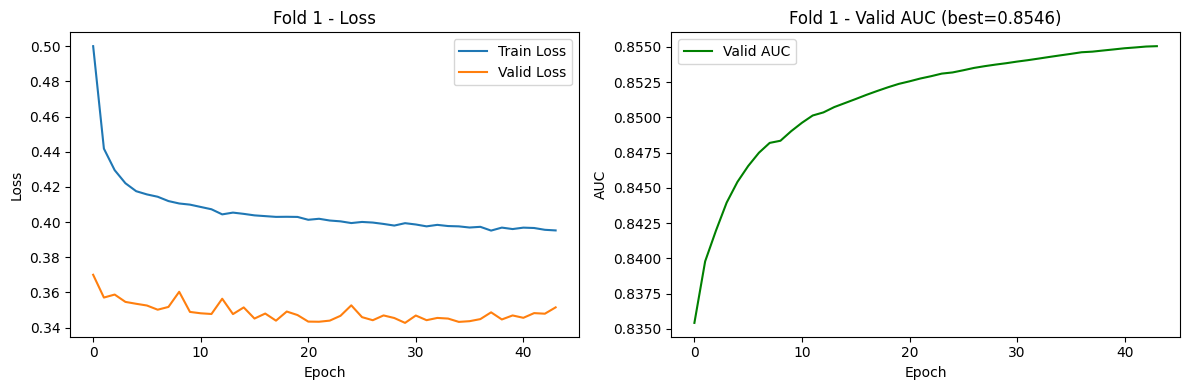

Fold 1 xong. Best valid AUC = 0.8546


In [11]:
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader

trained_models = []       # giữ 5 model đã train xong, ngay trong RAM
all_histories = []        # giữ lịch sử loss/auc từng fold để vẽ biểu đồ
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
i=1
print(f"\n{'='*50}\nFOLD {i}\n{'='*50}")

 # ---- Chuẩn bị data ----
train_dataset = DTransformerDataset(df_train_valid, config['num_concepts'], fold=i, is_train=True)
valid_dataset = DTransformerDataset(df_train_valid, config['num_concepts'], fold=i, is_train=False)
train_loader = DataLoader(train_dataset, batch_size=config["batch_size"], shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=config["batch_size"], shuffle=False)

model = DTransformer(
    num_questions=config['num_questions'],
    num_concepts=config['num_concepts'],
    d_model=config['d_model'],
    d_ff=config['d_ff'],
    num_attn_heads=config['num_attn_heads'],
    n_know=config['n_know'],
    n_blocks=config['n_blocks'],
    dropout=config['dropout'],
    lambda_cl=config['lambda_cl'],
    hard_neg=config.get('hard_neg', False),
).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=config.get('lr', 1e-3))

model, history = train_epoch(
    model, train_loader, valid_loader, optimizer, device,
    num_epochs=config.get('num_epochs', 75),
    patience=config.get('patience', 5)
)

trained_models.append(model)     # lưu model (đã load best checkpoint) vào RAM
all_histories.append(history)

# ---- Vẽ biểu đồ cho fold này ----
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["train_loss"], label="Train Loss")
axes[0].plot(history["valid_loss"], label="Valid Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title(f"Fold {i} - Loss")
axes[0].legend()

axes[1].plot(history["valid_auc"], label="Valid AUC", color="green")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("AUC")
axes[1].set_title(f"Fold {i} - Valid AUC (best={history['best_auc']:.4f})")
axes[1].legend()

plt.tight_layout()
plt.show()          # hiển thị trực tiếp trong Kaggle notebook, không cần lưu file

print(f"Fold {i} xong. Best valid AUC = {history['best_auc']:.4f}")

    

In [12]:
test_dataset = DTransformerDataset(df_test, config['num_concepts'], fold=None, is_train=False)
test_loader = DataLoader(test_dataset, batch_size=config["batch_size"], shuffle=False)

test_results = []

for i, model in enumerate(trained_models):
    metrics = evaluate(model, test_loader, device, question_level=True)  # bật True nếu df_test có cột qidxs
    metrics["fold"] = i
    test_results.append(metrics)
    print(f"Fold {i} - Test: " + ", ".join(f"{k}={v:.4f}" for k, v in metrics.items() if k != "fold"))

Fold 0 - Test: auc=0.8133, acc=0.8243, rmse=0.3545, mae=0.2312, f1=0.8966, precision=0.8428, recall=0.9579


In [13]:
import numpy as np

metric_names = ["auc", "acc", "rmse", "mae", "f1", "precision", "recall"]

print(f"\n{'='*50}\nTỔNG HỢP KẾT QUẢ TEST (5-fold)\n{'='*50}")
for m in metric_names:
    values = [r[m] for r in test_results]
    print(f"{m.upper():10s}: {np.mean(values):.4f} ± {np.std(values):.4f}")


TỔNG HỢP KẾT QUẢ TEST (5-fold)
AUC       : 0.8133 ± 0.0000
ACC       : 0.8243 ± 0.0000
RMSE      : 0.3545 ± 0.0000
MAE       : 0.2312 ± 0.0000
F1        : 0.8966 ± 0.0000
PRECISION : 0.8428 ± 0.0000
RECALL    : 0.9579 ± 0.0000


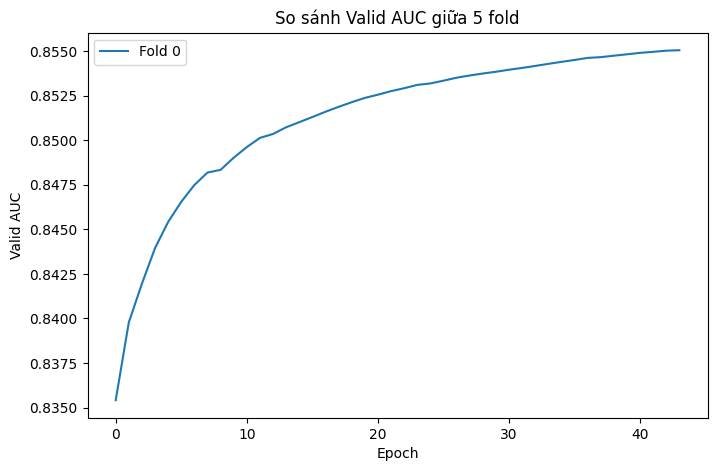

In [14]:
plt.figure(figsize=(8, 5))
for i, history in enumerate(all_histories):
    plt.plot(history["valid_auc"], label=f"Fold {i}")
plt.xlabel("Epoch")
plt.ylabel("Valid AUC")
plt.title("So sánh Valid AUC giữa 5 fold")
plt.legend()
plt.show()